# лабораторная работа 1

## повышение разрешения изображений

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from skimage import data
from pathlib import Path

np.random.seed(12)
torch.manual_seed(12)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

scale = 4
result_dir = Path("results")
result_dir.mkdir(exist_ok=True)

print("устройство для обучения -", device)

устройство для обучения - cpu


## подготовка изображения

In [2]:
photo_path = None
for name in ("photo.jpg", "photo.png"):
    if Path(name).exists():
        photo_path = Path(name)
        break

if photo_path is not None:
    photo = cv2.imread(str(photo_path))
    if photo is None:
        raise ValueError("не удалось открыть фото")
    photo = cv2.cvtColor(photo, cv2.COLOR_BGR2RGB)
else:
    photo = data.chelsea()

h, w = photo.shape[:2]
h = h - h % scale
w = w - w % scale
photo = photo[:h, :w]

small = cv2.resize(photo, (w // scale, h // scale), interpolation=cv2.INTER_AREA)
bicubic = cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)

print("размер исходного фото -", w, "x", h)
print("размер уменьшенного фото -", w // scale, "x", h // scale)

размер исходного фото - 448 x 300
размер уменьшенного фото - 112 x 75


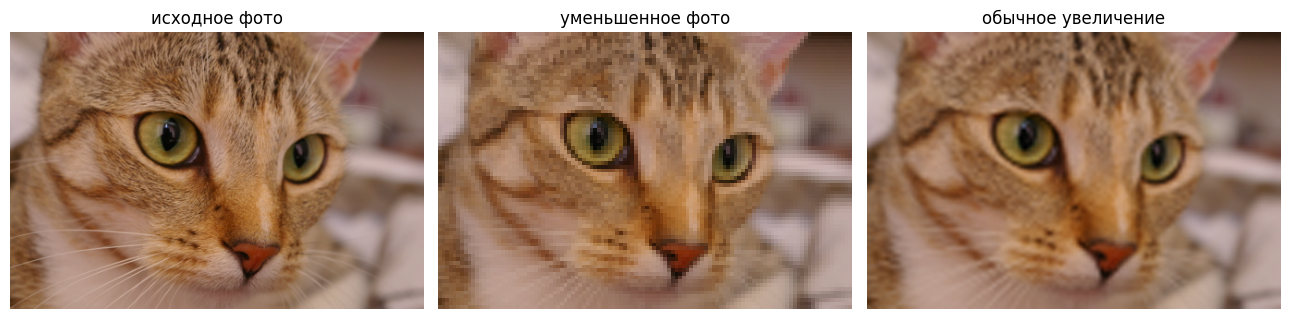

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(photo)
ax[0].set_title("исходное фото")
ax[1].imshow(small)
ax[1].set_title("уменьшенное фото")
ax[2].imshow(bicubic)
ax[2].set_title("обычное увеличение")

for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

## создание обучающих данных

In [4]:
train_photos = [data.astronaut(), data.coffee(), data.rocket()]
random = np.random.default_rng(12)
small_patches = []
big_patches = []

for image in train_photos:
    height, width = image.shape[:2]
    for i in range(64):
        y = random.integers(0, height - 96 + 1)
        x = random.integers(0, width - 96 + 1)
        big_patch = image[y:y + 96, x:x + 96]
        small_patch = cv2.resize(big_patch, (24, 24), interpolation=cv2.INTER_AREA)
        big_patches.append(big_patch)
        small_patches.append(small_patch)

x_train = torch.tensor(np.array(small_patches), dtype=torch.float32).permute(0, 3, 1, 2) / 255
y_train = torch.tensor(np.array(big_patches), dtype=torch.float32).permute(0, 3, 1, 2) / 255

train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=12, shuffle=True)
print("пар изображений для обучения -", len(x_train))

пар изображений для обучения - 192


## модель для увеличения изображения

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(32, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 32, 3, padding=1)

    def forward(self, x):
        y = F.relu(self.conv1(x))
        return x + self.conv2(y) * 0.2


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.first = nn.Conv2d(3, 32, 3, padding=1)
        self.block1 = ResidualBlock()
        self.block2 = ResidualBlock()
        self.up1 = nn.Conv2d(32, 128, 3, padding=1)
        self.up2 = nn.Conv2d(32, 128, 3, padding=1)
        self.last = nn.Conv2d(32, 3, 3, padding=1)

        nn.init.zeros_(self.last.weight)
        nn.init.zeros_(self.last.bias)

    def forward(self, x):
        base = F.interpolate(x, scale_factor=4, mode="bicubic", align_corners=False)
        y = F.relu(self.first(x))
        y = self.block1(y)
        y = self.block2(y)
        y = F.pixel_shuffle(self.up1(y), 2)
        y = F.relu(y)
        y = F.pixel_shuffle(self.up2(y), 2)
        y = F.relu(y)
        return base + self.last(y)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.layers(x)


generator = Generator().to(device)
discriminator = Discriminator().to(device)

## обучение модели

In [6]:
optimizer_g = torch.optim.Adam(generator.parameters(), lr=0.0003)
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=0.0002)
loss_gan = nn.BCEWithLogitsLoss()

pretrain_epochs = 12
epochs = 14
loss_history = []

for epoch in range(epochs):
    generator.train()
    discriminator.train()
    total_loss = 0

    for low, high in train_loader:
        low = low.to(device)
        high = high.to(device)

        if epoch >= pretrain_epochs:
            fake = generator(low).detach()
            real_score = discriminator(high)
            fake_score = discriminator(fake)
            d_loss = (
                loss_gan(real_score, torch.ones_like(real_score)) +
                loss_gan(fake_score, torch.zeros_like(fake_score))
            ) / 2
            optimizer_d.zero_grad()
            d_loss.backward()
            optimizer_d.step()

        restored = generator(low)
        pixel_loss = F.l1_loss(restored, high)

        if epoch >= pretrain_epochs:
            score = discriminator(restored)
            g_loss = pixel_loss + 0.0005 * loss_gan(score, torch.ones_like(score))
        else:
            g_loss = pixel_loss

        optimizer_g.zero_grad()
        g_loss.backward()
        optimizer_g.step()
        total_loss += pixel_loss.item()

    avg_loss = total_loss / len(train_loader)
    loss_history.append(avg_loss)
    print("эпоха", epoch + 1, "ошибка l1 -", round(avg_loss, 4))

эпоха 1 ошибка l1 - 0.024
эпоха 2 ошибка l1 - 0.024
эпоха 3 ошибка l1 - 0.0239
эпоха 4 ошибка l1 - 0.0239
эпоха 5 ошибка l1 - 0.0239
эпоха 6 ошибка l1 - 0.0239
эпоха 7 ошибка l1 - 0.0238
эпоха 8 ошибка l1 - 0.0238
эпоха 9 ошибка l1 - 0.0237
эпоха 10 ошибка l1 - 0.0236
эпоха 11 ошибка l1 - 0.0236
эпоха 12 ошибка l1 - 0.0235
эпоха 13 ошибка l1 - 0.0234
эпоха 14 ошибка l1 - 0.0234


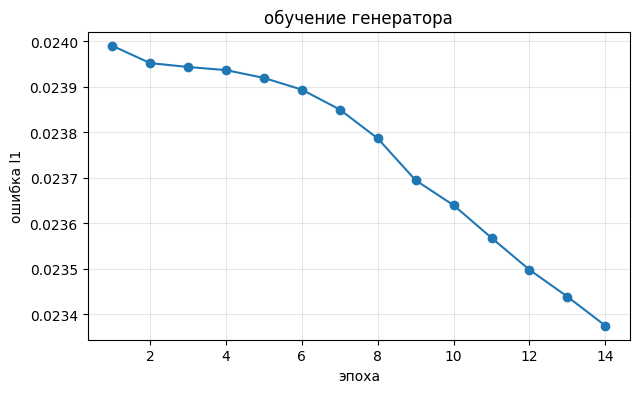

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), loss_history, marker="o")
plt.xlabel("эпоха")
plt.ylabel("ошибка l1")
plt.title("обучение генератора")
plt.grid(alpha=0.3)
plt.show()

## восстановление фотографии

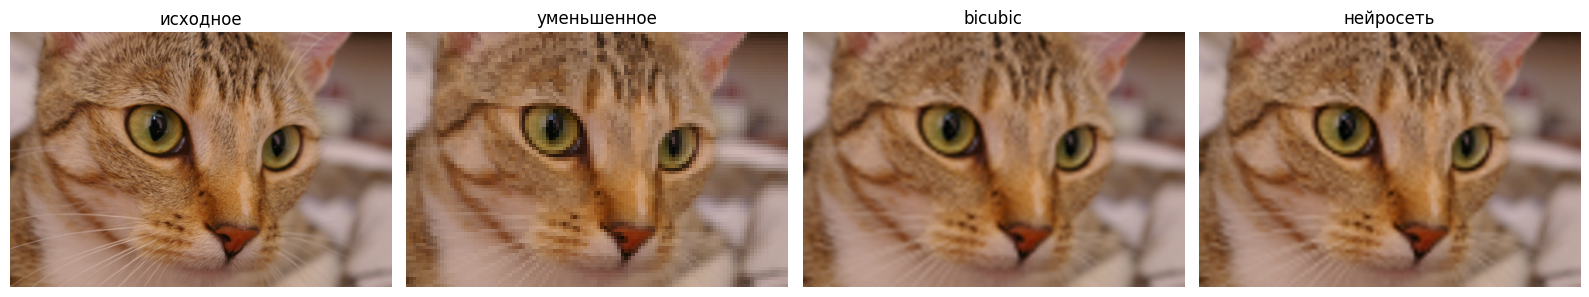

In [8]:
generator.eval()

low_tensor = torch.tensor(small, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)
low_tensor = low_tensor.to(device) / 255

with torch.no_grad():
    output = generator(low_tensor)

restored = output.squeeze(0).permute(1, 2, 0).cpu().numpy()
restored = np.uint8(np.clip(restored * 255, 0, 255))

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
titles = ["исходное", "уменьшенное", "bicubic", "нейросеть"]
images = [photo, small, bicubic, restored]

for a, image, name in zip(ax, images, titles):
    a.imshow(image)
    a.set_title(name)
    a.axis("off")

plt.tight_layout()
plt.show()

## оценка результата

In [9]:
def get_psnr(original, result):
    difference = original.astype(np.float32) - result.astype(np.float32)
    mse = np.mean(difference ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10(255 ** 2 / mse)


bicubic_psnr = get_psnr(photo, bicubic)
model_psnr = get_psnr(photo, restored)

print("psnr обычного увеличения -", round(bicubic_psnr, 2), "дб")
print("psnr нейросети -", round(model_psnr, 2), "дб")

if model_psnr > bicubic_psnr:
    print("по psnr нейросеть лучше обычного увеличения")
else:
    print("по psnr обычное увеличение пока лучше нейросети")

psnr обычного увеличения - 30.26 дб
psnr нейросети - 30.39 дб
по psnr нейросеть лучше обычного увеличения


## сохранение результата

In [10]:
cv2.imwrite(str(result_dir / "original.png"), cv2.cvtColor(photo, cv2.COLOR_RGB2BGR))
cv2.imwrite(str(result_dir / "small.png"), cv2.cvtColor(small, cv2.COLOR_RGB2BGR))
cv2.imwrite(str(result_dir / "bicubic.png"), cv2.cvtColor(bicubic, cv2.COLOR_RGB2BGR))
cv2.imwrite(str(result_dir / "restored.png"), cv2.cvtColor(restored, cv2.COLOR_RGB2BGR))
torch.save(generator.state_dict(), result_dir / "generator.pth")

## вывод

в ходе работы получилось уменьшить исходную фотографию и восстановить ее размер с помощью генератора. была реализована простая модель по мотивам srgan и проведено сравнение с bicubic.

качество зависит от набора фотографий и времени обучения. на небольшом наборе изображений нейросеть не всегда показывает результат лучше обычного увеличения, поэтому для более качественного восстановления понадобится больше данных и эпох.